# PlantWild WavestarNet WaveDown: Sealed Final Holdout

## TL;DR

This notebook evaluates the frozen full WavestarNet and parameter-matched conventional-downsampling ablation exactly once on the locked 1,523-image test set. No training, selection, or tuning occurs here.

## Context & Methods

The primary endpoint is macro-F1. Accuracy, balanced accuracy, weighted-F1, NLL, Brier score, and 15-bin ECE are secondary. All six validation-selected checkpoints (three seeds per variant) are checked for hash identity and strict state-dict loading before inference.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd().resolve()
for candidate in (REPO_ROOT, *REPO_ROOT.parents):
    if (candidate / 'code' / 'plantwild' / 'wavedown_ablation' / 'sealed_test.py').is_file():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError('Open this notebook inside the Agrivision4 workspace')
CODE_ROOT = REPO_ROOT / 'code'
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))
RUN_MODE = 'report_existing'  # preflight | sealed_evaluation | report_existing
SEALED_ACKNOWLEDGEMENT = 'RUN_PLANTWILD_WAVEDOWN_FINAL_HOLDOUT_ONCE'
ACKNOWLEDGEMENT = ''
DEVICE = 'auto'
BATCH_SIZE = 64
NUM_WORKERS = 0
print({'repo_root': str(REPO_ROOT), 'run_mode': RUN_MODE, 'device': DEVICE})

{'repo_root': '/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4', 'run_mode': 'report_existing', 'device': 'auto'}


## Data

The evaluator checks the test-manifest hash, 105-class mapping, sample count, component isolation, image availability, and all checkpoint identities before any inference.

In [2]:
from plantwild.wavedown_ablation.sealed_test import build_spec, execute

spec = build_spec(REPO_ROOT)
result = execute(spec, run_mode=RUN_MODE, acknowledgement=ACKNOWLEDGEMENT, device=DEVICE, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
print({'status': result['status'], 'sealed_inference_executed': result.get('sealed_inference_executed', False)})

{'status': 'report_loaded', 'sealed_inference_executed': False}


## Results

### Per-seed test metrics

,accuracy,balanced_accuracy,macro_f1,weighted_f1,nll,brier,ece_15bin,variant,display_name,seed,parameters,checkpoint_sha256,runtime_seconds
0,0.50952,0.45254,0.44286,0.50522,2.16188,0.65863,0.09796,full_wavestarnet,WavestarNet,42,3013109,7c6028da2f1b1977953d54146683f4a2020459c88d115c...,140.32880
1,0.51806,0.45877,0.45553,0.51414,2.07729,0.64051,0.09529,full_wavestarnet,WavestarNet,2024,3013109,e13f8002041a02ed9aef21a8c4818e3c1ecde66d6afb47...,84.14301
2,0.52856,0.46420,0.45650,0.52563,2.10773,0.64503,0.09674,full_wavestarnet,WavestarNet,3407,3013109,a9cc947a81384fc367471ec547de760a32cd07ac44a2f5...,71.11748
3,0.50033,0.44114,0.42963,0.49453,2.21116,0.64881,0.04052,parameter_matched_conventional_downsampling,WavestarNet (parameter-matched conventional do...,42,3012029,09551dc5284aa88c2fa4e304b72ba45e9b4cc249cf3f9f...,64.56508
4,0.51609,0.44737,0.43726,0.50630,2.21100,0.63901,0.04243,parameter_matched_conventional_downsampling,WavestarNet (parameter-matched conventional do...,2024,3012029,5225c1186c29b32eb404e31c38bb833d47eac439693724...,63.06478
5,0.51412,0.44296,0.43429,0.50589,2.21171,0.64537,0.03924,parameter_matched_conventional_downsampling,WavestarNet (parameter-matched conventional do...,3407,3012029,be4d75659e980325593560e740ac7fed9fdf8fea931821...,63.75693


### Three-seed aggregate

,variant,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,nll_mean,nll_std,brier_mean,brier_std,ece_15bin_mean,ece_15bin_std
0,full_wavestarnet,0.51871,0.00954,0.45850,0.00583,0.45163,0.00761,0.51499,0.01023,2.11564,0.04285,0.64806,0.00943,0.09666,0.00134
1,parameter_matched_conventional_downsampling,0.51018,0.00859,0.44382,0.00320,0.43373,0.00385,0.50224,0.00668,2.21129,0.00037,0.64440,0.00497,0.04073,0.00161


### Paired full-WavestarNet minus WaveDown difference

,metric,full_wavestarnet_mean,wavedown_ablation_mean,full_minus_ablation,seed_sd,full_minus_ablation_pp
0,accuracy,0.51871,0.51018,0.00854,0.00626,0.85358
1,balanced_accuracy,0.45850,0.44382,0.01468,0.00568,1.46801
2,macro_f1,0.45163,0.43373,0.01790,0.00450,1.79022
3,weighted_f1,0.51499,0.50224,0.01275,0.00621,1.27540
4,nll,2.11564,2.21129,-0.09566,0.04283,-9.56564
5,brier,0.64806,0.64440,0.00366,0.00541,0.36592
6,ece_15bin,0.09666,0.04073,0.05593,0.00266,5.59330


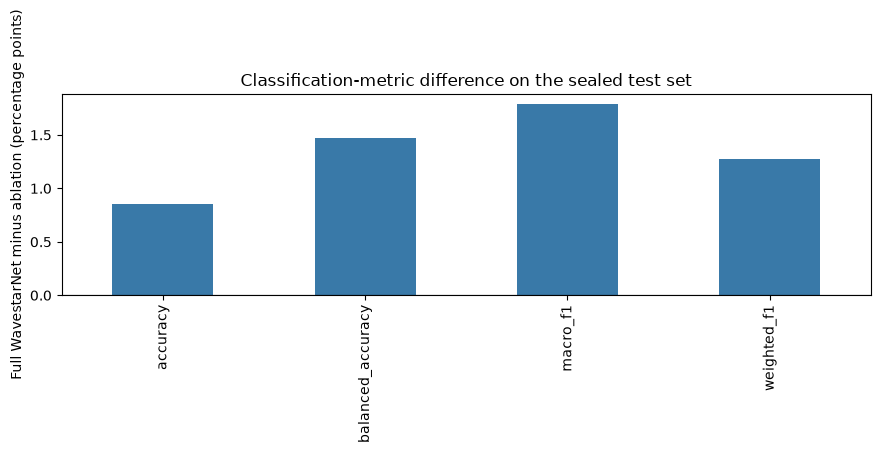

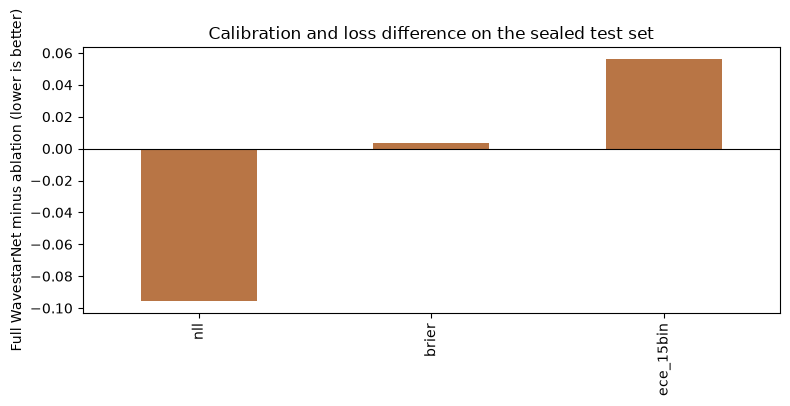

### Largest absolute per-class F1 differences

,class_name,support,full_wavestarnet_f1_mean,wavedown_ablation_f1_mean,full_minus_ablation_f1
22,broccoli alternaria leaf spot,6,0.1222,0.3744,-0.2522
37,coffee berry blotch,11,0.3723,0.5830,-0.2107
83,tobacco blue mold,7,0.1689,0.3657,-0.1967
21,blueberry scorch,6,0.2491,0.3675,-0.1184
14,bell pepper bacterial spot,9,0.1508,0.2626,-0.1118
16,bell pepper powdery mildew,3,0.0000,0.1111,-0.1111
64,plum pocket disease,8,0.1554,0.2626,-0.1072
62,peach scab,10,0.6010,0.4947,0.1063
20,blueberry rust,6,0.2559,0.1481,0.1077
31,celery anthracnose,4,0.2063,0.0952,0.1111


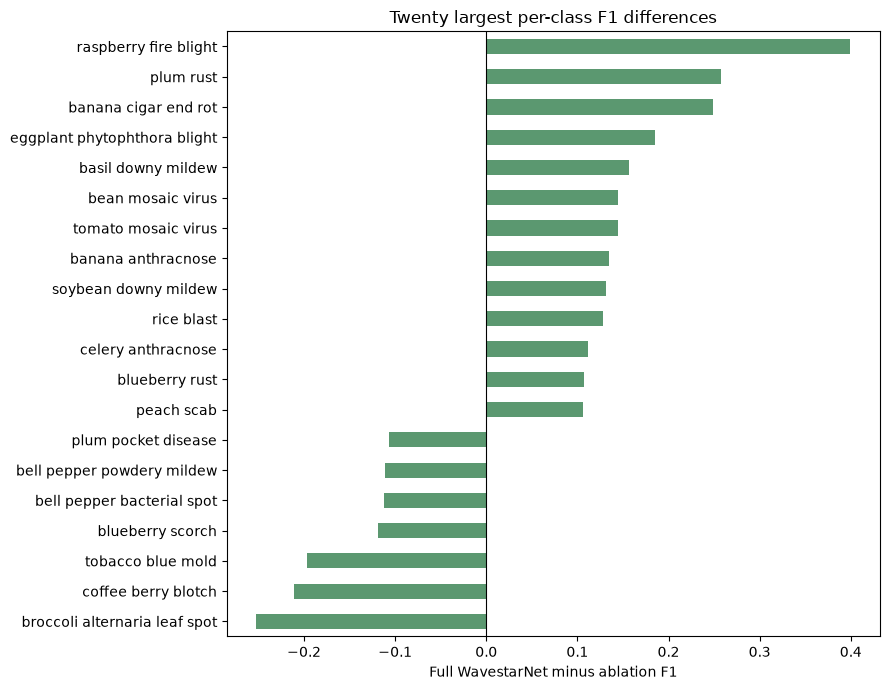

**Saved result bundle:** `/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/plantwild/results/sealed_test/plantwild_wavestarnet_wavedown_final_holdout_v01`  
**ZIP:** `/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/plantwild/results/sealed_test/plantwild_wavestarnet_wavedown_final_holdout_v01.zip`

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

if RUN_MODE == 'preflight':
    display(Markdown('### Preflight passed — no test inference executed'))
    display(pd.DataFrame([{key: result[key] for key in ('test_samples', 'class_count', 'test_manifest_sha256')}]))
    display(pd.DataFrame(result['strict_load_audits']))
else:
    display(Markdown('### Per-seed test metrics'))
    display(result['seed_metrics'].sort_values(['variant', 'seed']).round(5))
    display(Markdown('### Three-seed aggregate'))
    display(result['aggregate'].round(5))
    paired = result['paired'].copy()
    paired['full_minus_ablation_pp'] = paired['full_minus_ablation'] * 100
    display(Markdown('### Paired full-WavestarNet minus WaveDown difference'))
    display(paired.round(5))
    plot = paired[paired.metric.isin(['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1'])]
    ax = plot.plot.bar(x='metric', y='full_minus_ablation_pp', legend=False, color='#3979a8', figsize=(9, 4))
    ax.axhline(0, color='black', linewidth=0.8); ax.set_ylabel('Full WavestarNet minus ablation (percentage points)'); ax.set_xlabel('')
    ax.set_title('Classification-metric difference on the sealed test set'); plt.tight_layout(); plt.show()
    loss = paired[paired.metric.isin(['nll', 'brier', 'ece_15bin'])]
    ax = loss.plot.bar(x='metric', y='full_minus_ablation', legend=False, color='#b87545', figsize=(8, 4))
    ax.axhline(0, color='black', linewidth=0.8); ax.set_ylabel('Full WavestarNet minus ablation (lower is better)'); ax.set_xlabel('')
    ax.set_title('Calibration and loss difference on the sealed test set'); plt.tight_layout(); plt.show()
    per_class = result['per_class'].copy()
    per_class['absolute_delta'] = per_class['full_minus_ablation_f1'].abs()
    largest = per_class.sort_values('absolute_delta', ascending=False).head(20).sort_values('full_minus_ablation_f1')
    display(Markdown('### Largest absolute per-class F1 differences'))
    display(largest[['class_name', 'support', 'full_wavestarnet_f1_mean', 'wavedown_ablation_f1_mean', 'full_minus_ablation_f1']].round(4))
    ax = largest.plot.barh(x='class_name', y='full_minus_ablation_f1', legend=False, color='#5b9870', figsize=(9, 7))
    ax.axvline(0, color='black', linewidth=0.8); ax.set_xlabel('Full WavestarNet minus ablation F1'); ax.set_ylabel('')
    ax.set_title('Twenty largest per-class F1 differences'); plt.tight_layout(); plt.show()
    display(Markdown(f"**Saved result bundle:** `{result['output_directory']}`  \n**ZIP:** `{result['zip_path']}`"))

## Takeaways

Interpret the paired point estimates and uncertainty as final test results. They must not be used to choose a new architecture, checkpoint, or training recipe.